Region,Record Count,Share of Records,New Visitors,Pageviews,Total Duration
Italy,24,32.9%,5,650,6:54:27
United States,28,38.4%,13,46,0:10:32
China,18,24.7%,18,19,0:02:30
Singapore,1,1.4%,1,1,0:00:10
France,2,2.7%,2,2,0:00:02


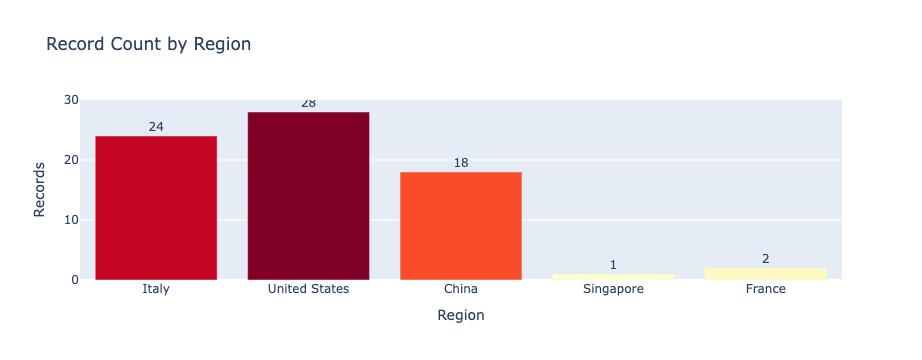

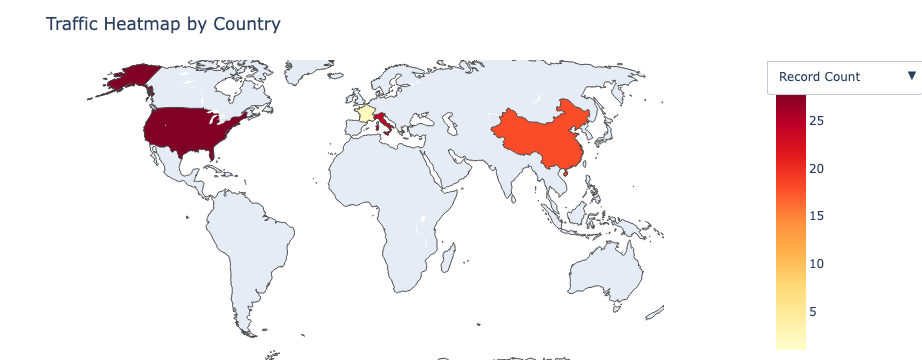

In [18]:
!pip install plotly pandas openpyxl

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

df = pd.DataFrame({
    "Region": ["Italy", "United States", "China", "Singapore", "France"],
    "ISO3": ["ITA", "USA", "CHN", "SGP", "FRA"],
    "Record Count": [24, 28, 18, 1, 2],
    "Share of Records": [0.329, 0.384, 0.247, 0.014, 0.027],
    "New Visitors": [5, 13, 18, 1, 2],
    "Pageviews": [650, 46, 19, 1, 2],
    "Total Duration": ["6:54:27", "0:10:32", "0:02:30", "0:00:10", "0:00:02"],
    "Duration (seconds)": [24867, 632, 150, 10, 2],
})

display(
    df[["Region", "Record Count", "Share of Records", "New Visitors", "Pageviews", "Total Duration"]]
    .style.format({"Share of Records": "{:.1%}"})
    .hide(axis="index")
)

fig_bar = px.bar(
    df,
    x="Region",
    y="Record Count",
    text="Record Count",
    color="Record Count",
    color_continuous_scale="YlOrRd",
    title="Record Count by Region",
)
fig_bar.update_traces(textposition="outside")
fig_bar.update_layout(
    xaxis_title="Region",
    yaxis_title="Records",
    height=500,
    coloraxis_showscale=False,
)
fig_bar.show()

metrics = {
    "Record Count": "YlOrRd",
    "Pageviews": "Blues",
    "New Visitors": "Greens",
    "Duration (seconds)": "Oranges",
}

fig_map = go.Figure()

for i, (metric, scale) in enumerate(metrics.items()):
    fig_map.add_trace(
        go.Choropleth(
            locations=df["ISO3"],
            locationmode="ISO-3",
            z=df[metric],
            text=df["Region"],
            colorscale=scale,
            colorbar=dict(title=metric),
            visible=(i == 0),
            hovertemplate=(
                "<b>%{text}</b><br>"
                + metric
                + ": %{z}<br>"
                + "<extra></extra>"
            ),
        )
    )

buttons = []
for i, metric in enumerate(metrics.keys()):
    visible = [False] * len(metrics)
    visible[i] = True
    buttons.append(dict(label=metric, method="update", args=[{"visible": visible}]))

fig_map.update_layout(
    title="Traffic Heatmap by Country",
    geo=dict(showframe=False, showcoastlines=True, projection_type="natural earth"),
    updatemenus=[dict(buttons=buttons, direction="down", x=1.02, y=1, xanchor="left")],
    margin=dict(l=0, r=0, t=60, b=0),
    height=560,
)

fig_map.show()